### 1. Import Library

In [1]:
#202431013_Tashfia Wahdah Fuady
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

### 2. Membaca Dataset

In [2]:
#202431013_Tashfia Wahdah Fuady
df = pd.read_csv("data_sekolah_indonesia_final.csv")

display(df.head())
print("Ukuran dataset:", df.shape)

,Provinsi,Kabupaten_Kota,SD_Negeri,SD_Swasta,Jumlah_SD,SMP_Negeri,SMP_Swasta,Jumlah_SMP,SMA_Negeri,SMA_Swasta,Jumlah_SMA,SMK_Negeri,SMK_Swasta,Jumlah_SMK,Total_Seluruh_Sekolah
0,Tidak diketahui,Kab. Aceh Besar,247.0,15,262,60,48,108,34,34,68,8,3,11,449
1,Tidak diketahui,Kab. Pidie,325.0,14,339,65,35,100,32,19,51,7,7,14,504
2,Tidak diketahui,Kab. Aceh Utara,395.0,17,412,107,85,192,43,39,82,14,10,24,710
3,Tidak diketahui,Kab. Aceh Timur,317.0,18,335,82,30,112,32,16,48,14,1,15,510
4,Tidak diketahui,Kab. Aceh Tengah,207.0,19,226,50,21,71,21,15,36,4,1,5,338


Ukuran dataset: (481, 15)


### 3. Melihat Informasi Data

In [3]:
#202431013_Tashfia Wahdah Fuady
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 481 entries, 0 to 480
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Provinsi               481 non-null    str    
 1   Kabupaten_Kota         481 non-null    str    
 2   SD_Negeri              480 non-null    float64
 3   SD_Swasta              481 non-null    int64  
 4   Jumlah_SD              481 non-null    int64  
 5   SMP_Negeri             481 non-null    int64  
 6   SMP_Swasta             481 non-null    int64  
 7   Jumlah_SMP             481 non-null    int64  
 8   SMA_Negeri             481 non-null    int64  
 9   SMA_Swasta             481 non-null    int64  
 10  Jumlah_SMA             481 non-null    int64  
 11  SMK_Negeri             481 non-null    int64  
 12  SMK_Swasta             481 non-null    int64  
 13  Jumlah_SMK             481 non-null    int64  
 14  Total_Seluruh_Sekolah  481 non-null    int64  
dtypes: float64(1), in

### 4. Melihat Deskripsi Statistik

In [4]:
#202431013_Tashfia Wahdah Fuady
df.describe()

,SD_Negeri,SD_Swasta,Jumlah_SD,SMP_Negeri,SMP_Swasta,Jumlah_SMP,SMA_Negeri,SMA_Swasta,Jumlah_SMA,SMK_Negeri,SMK_Swasta,Jumlah_SMK,Total_Seluruh_Sekolah
count,480.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000,481.000000
mean,264.118750,79.794179,340.744283,48.436590,63.952183,112.399168,14.646570,28.199584,42.846154,6.875260,20.767152,27.642412,504.696466
std,238.613139,112.292240,320.669506,29.794236,99.106739,116.244331,8.823019,38.777862,43.275345,4.168962,35.466472,37.169334,485.432092
min,17.000000,0.000000,23.000000,4.000000,0.000000,7.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,34.000000
25%,96.750000,15.000000,123.000000,27.000000,12.000000,44.000000,8.000000,7.000000,17.000000,4.000000,2.000000,8.000000,190.000000
50%,183.500000,37.000000,228.000000,44.000000,27.000000,76.000000,13.000000,14.000000,29.000000,6.000000,7.000000,14.000000,346.000000
75%,364.000000,93.000000,428.000000,65.000000,65.000000,135.000000,19.000000,29.000000,49.000000,9.000000,25.000000,30.000000,638.000000
max,1545.000000,912.000000,2457.000000,174.000000,929.000000,1036.000000,67.000000,235.000000,284.000000,34.000000,350.000000,361.000000,4138.000000


### 5. Mengecek Data Kosong

In [5]:
#202431013_Tashfia Wahdah Fuady
print("Jumlah data kosong:")
print(df.isna().sum())

Jumlah data kosong:
Provinsi                 0
Kabupaten_Kota           0
SD_Negeri                1
SD_Swasta                0
Jumlah_SD                0
SMP_Negeri               0
SMP_Swasta               0
Jumlah_SMP               0
SMA_Negeri               0
SMA_Swasta               0
Jumlah_SMA               0
SMK_Negeri               0
SMK_Swasta               0
Jumlah_SMK               0
Total_Seluruh_Sekolah    0
dtype: int64


### 6. Melihat Isi Unik Kolom Target

In [6]:
#202431013_Tashfia Wahdah Fuady
# Membuat kategori berdasarkan jumlah SD
df["Kategori_SD"] = pd.qcut(
    df["Jumlah_SD"],
    q=3,
    labels=["Rendah", "Sedang", "Tinggi"]
)

print("Kategori target:")
print(df["Kategori_SD"].unique())

print("\nJumlah data setiap kategori:")
print(df["Kategori_SD"].value_counts())

# Arti setiap kelas:
# Rendah = Wilayah dengan jumlah SD relatif sedikit
# Sedang = Wilayah dengan jumlah SD tingkat menengah
# Tinggi = Wilayah dengan jumlah SD relatif banyak

Kategori target:
['Sedang', 'Tinggi', 'Rendah']
Categories (3, str): ['Rendah' < 'Sedang' < 'Tinggi']

Jumlah data setiap kategori:
Kategori_SD
Rendah    161
Sedang    161
Tinggi    159
Name: count, dtype: int64


### 7. Memisahkan Fitur X dan Target Y

In [7]:
#202431013_Tashfia Wahdah Fuady
X = df[["Jumlah_SMP", "Jumlah_SMA", "Jumlah_SMK"]]
y = df["Kategori_SD"]

print("Fitur X:")
display(X.head())

print("\nTarget Y:")
display(y.head())

Fitur X:


,Jumlah_SMP,Jumlah_SMA,Jumlah_SMK
0,108,68,11
1,100,51,14
2,192,82,24
3,112,48,15
4,71,36,5



Target Y:


0    Sedang
1    Tinggi
2    Tinggi
3    Tinggi
4    Sedang
Name: Kategori_SD, dtype: category
Categories (3, str): ['Rendah' < 'Sedang' < 'Tinggi']

### 8. Mengubah X dan Y Menjadi Array Angka

In [8]:
#202431013_Tashfia Wahdah Fuady
le = LabelEncoder()

X = np.array(X, dtype=np.float64)
y = le.fit_transform(y)

y = np.array(y, dtype=np.int64)

print("Bentuk X:", X.shape)
print("Bentuk Y:", y.shape)

print("\nKode kategori:")
for i, kelas in enumerate(le.classes_):
    print(i, "=", kelas)

Bentuk X: (481, 3)
Bentuk Y: (481,)

Kode kategori:
0 = Rendah
1 = Sedang
2 = Tinggi


### 9. Membagi Data Training dan Testing

In [9]:
#202431013_Tashfia Wahdah Fuady
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=0
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 336
Jumlah data uji: 145


### 10. Membuat dan Melatih Model Decision Tree

In [10]:
#202431013_Tashfia Wahdah Fuady
model = DecisionTreeClassifier(max_depth=3)

model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")

Model Decision Tree berhasil dilatih.


### 11. Visualisasi Pohon Keputusan

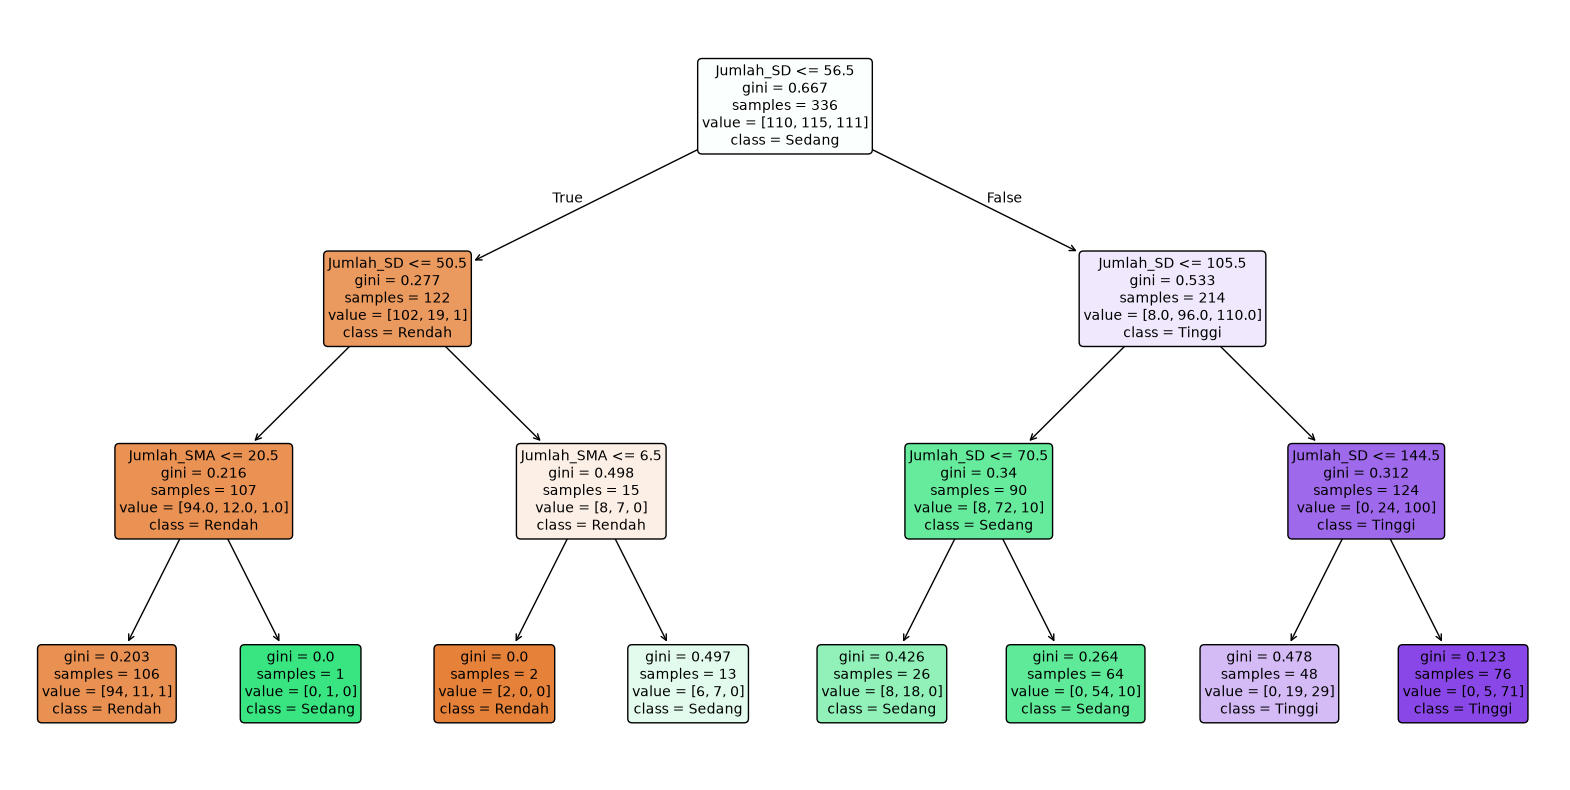

In [11]:
#202431013_Tashfia Wahdah Fuady
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=["Jumlah_SD", "Jumlah_SMP", "Jumlah_SMA", "Jumlah_SMK"],
    class_names=le.classes_,
    filled=True,
    rounded=True
)

plt.show()

### 12. Menguji dengan Satu Data Baru

In [12]:
#202431013_Tashfia Wahdah Fuady
data_baru = np.array([[50, 30, 20]], dtype=np.float64)

prediksi = model.predict(data_baru)

print("Hasil prediksi:", le.inverse_transform(prediksi)[0])

Hasil prediksi: Rendah


### 13. Menghitung Akurasi

In [13]:
#202431013_Tashfia Wahdah Fuady
y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model:", akurasi)
print("Akurasi dalam persen:", akurasi * 100, "%")

Akurasi Model: 0.8137931034482758
Akurasi dalam persen: 81.37931034482759 %


### 14. Menampilkan Classification Report

In [14]:
#202431013_Tashfia Wahdah Fuady
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.89      0.82      0.86        51
      Sedang       0.68      0.78      0.73        46
      Tinggi       0.89      0.83      0.86        48

    accuracy                           0.81       145
   macro avg       0.82      0.81      0.81       145
weighted avg       0.82      0.81      0.82       145

